In [15]:

import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Step 1: Load FD001 data directly from /content/
columns = (
    ["unit", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df = pd.read_csv(
    "/content/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    "/content/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    "/content/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("RUL shape:", rul_df.shape)

# Step 2: Remove the seven proposed low-variance sensors
low_variance_sensors = [
    "sensor_1", "sensor_5", "sensor_6",
    "sensor_10", "sensor_16", "sensor_18",
    "sensor_19"
]

train_clean = train_df.drop(
    columns=low_variance_sensors
).copy()

test_clean = test_df.drop(
    columns=low_variance_sensors
).copy()

# Step 3: Remove sensor 9 as proposed
train_clean = train_clean.drop(columns=["sensor_9"])
test_clean = test_clean.drop(columns=["sensor_9"])

# Step 4: List the remaining sensors
remaining_sensors = [
    f"sensor_{i}" for i in range(1, 22)
    if f"sensor_{i}" not in low_variance_sensors
    and f"sensor_{i}" != "sensor_9"
]

# Step 5: Calculate VIF on training data
X = train_clean[remaining_sensors].astype(float)

# Remove any additional constant features
X = X.loc[:, X.nunique() > 1]

vif_table = pd.DataFrame({
    "Sensor": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
}).sort_values("VIF", ascending=False)

print("\nClean train shape:", train_clean.shape)
print("Clean test shape:", test_clean.shape)
print("\nRemaining sensors:")
print(X.columns.tolist())

print("\nVIF results:")
display(vif_table)


Train shape: (20631, 26)
Test shape: (13096, 26)
RUL shape: (100, 1)

Clean train shape: (20631, 18)
Clean test shape: (13096, 18)

Remaining sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

VIF results:


,Sensor,VIF
5,sensor_11,5.982627
6,sensor_12,5.259848
4,sensor_8,4.708570
7,sensor_13,4.696566
2,sensor_4,4.566860
3,sensor_7,4.326725
9,sensor_15,3.292105
12,sensor_21,3.099379
11,sensor_20,3.057793
0,sensor_2,2.636436


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [17]:

import numpy as np
import pandas as pd

# 1. Use the pruned data from Step 1
train_fd001_pruned = train_clean.copy()
test_fd001_pruned = test_clean.copy()

# 2. Use the actual cycle column name
healthy_train_data = train_fd001_pruned[
    train_fd001_pruned["cycle"] <= 20
]

# 3. Calculate healthy-baseline mean and standard deviation
healthy_mu = healthy_train_data[remaining_sensors].mean()
healthy_sigma = healthy_train_data[remaining_sensors].std(ddof=0)

# 4. Avoid division by zero
healthy_sigma = healthy_sigma.replace(0, 1e-8)

# 5. Normalize both datasets using training baseline parameters
train_fd001_norm = train_fd001_pruned.copy()
test_fd001_norm = test_fd001_pruned.copy()

train_fd001_norm[remaining_sensors] = (
    train_fd001_pruned[remaining_sensors] - healthy_mu
) / healthy_sigma

test_fd001_norm[remaining_sensors] = (
    test_fd001_pruned[remaining_sensors] - healthy_mu
) / healthy_sigma

# 6. Display results
print("Healthy-Baseline Normalization Complete.")
print("Healthy baseline rows:", len(healthy_train_data))
print("Number of sensors:", len(remaining_sensors))
print("Normalized train shape:", train_fd001_norm.shape)
print("Normalized test shape:", test_fd001_norm.shape)

display(train_fd001_norm.head())


Healthy-Baseline Normalization Complete.
Healthy baseline rows: 2000
Number of sensors: 13
Normalized train shape: (20631, 18)
Normalized test shape: (13096, 18)


,unit,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,-1.463802,0.624110,-0.363667,0.656684,0.029707,0.657534,-0.492617,-0.652313,0.158496,0.045539,-0.227198,0.979174,0.738638
1,1,2,0.0019,-0.0003,100.0,-0.602381,1.086709,0.064308,-0.321777,-0.331470,0.769431,0.729708,0.260141,-0.747686,0.508704,-0.227198,0.517245,0.796301
2,1,3,-0.0043,0.0003,100.0,-0.080308,0.250975,0.242912,0.496280,0.390883,-0.461435,1.005717,-0.469822,-0.526542,-0.018476,-1.971520,0.132304,-0.199010
3,1,4,0.0007,0.0000,100.0,-0.080308,-0.883702,-0.149679,0.801047,0.932648,-1.244714,1.873173,0.442631,-0.450285,-1.886199,-0.227198,-0.406613,0.173291
4,1,5,-0.0019,-0.0002,100.0,-0.028101,-0.870610,0.583270,0.079231,0.029707,-0.405487,0.552274,-0.287332,-0.454098,0.418330,0.644963,-0.252637,0.555621


In [18]:

import numpy as np
import pandas as pd

# ============================================================
# STEP 3: Causal EWMA Smoothing and Health State Labeling
# ============================================================

ALPHA = 0.25

# Work on copies to preserve Step 2 outputs
train_fd001_step3 = train_fd001_norm.copy()
test_fd001_step3 = test_fd001_norm.copy()

# ------------------------------------------------------------
# 1. Calculate true RUL for training data
# RUL = last cycle of each engine - current cycle
# ------------------------------------------------------------
last_cycle = train_fd001_step3.groupby("unit")["cycle"].transform("max")

train_fd001_step3["RUL"] = (
    last_cycle - train_fd001_step3["cycle"]
)

# ------------------------------------------------------------
# 2. Assign three health states
# Normal:  RUL > 80
# Warning: 30 < RUL <= 80
# Fault:   RUL <= 30
# ------------------------------------------------------------
def assign_health_state(rul):
    if rul > 80:
        return "Normal"
    elif rul > 30:
        return "Warning"
    else:
        return "Fault"

train_fd001_step3["health_state"] = (
    train_fd001_step3["RUL"].apply(assign_health_state)
)

# ------------------------------------------------------------
# 3. Apply causal EWMA to sensor columns
# Group by engine and preserve chronological order
# ------------------------------------------------------------
for sensor in remaining_sensors:
    train_fd001_step3[sensor] = (
        train_fd001_step3
        .groupby("unit", sort=False)[sensor]
        .transform(lambda s: s.ewm(
            alpha=ALPHA,
            adjust=False
        ).mean())
    )

    test_fd001_step3[sensor] = (
        test_fd001_step3
        .groupby("unit", sort=False)[sensor]
        .transform(lambda s: s.ewm(
            alpha=ALPHA,
            adjust=False
        ).mean())
    )

# ------------------------------------------------------------
# 4. Display and validate results
# ------------------------------------------------------------
print("Step 3 completed.")
print("\nTraining shape:", train_fd001_step3.shape)
print("Testing shape:", test_fd001_step3.shape)

print("\nHealth-state counts:")
display(train_fd001_step3["health_state"].value_counts())

print("\nTraining preview:")
display(train_fd001_step3.head())

print("\nRUL and health-state boundary check:")
display(
    train_fd001_step3.loc[
        train_fd001_step3["RUL"].isin([30, 31, 80, 81]),
        ["unit", "cycle", "RUL", "health_state"]
    ].head(12)
)


Step 3 completed.

Training shape: (20631, 20)
Testing shape: (13096, 18)

Health-state counts:


,count
health_state,
Normal,12531
Warning,5000
Fault,3100



Training preview:


,unit,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL,health_state
0,1,1,-0.0007,-0.0004,100.0,-1.463802,0.624110,-0.363667,0.656684,0.029707,0.657534,-0.492617,-0.652313,0.158496,0.045539,-0.227198,0.979174,0.738638,191,Normal
1,1,2,0.0019,-0.0003,100.0,-1.248447,0.739760,-0.256673,0.412069,-0.060587,0.685509,-0.187035,-0.424200,-0.068049,0.161330,-0.227198,0.863692,0.753054,190,Normal
2,1,3,-0.0043,0.0003,100.0,-0.956412,0.617564,-0.131777,0.433122,0.052280,0.398773,0.111153,-0.435605,-0.182672,0.116379,-0.663278,0.680845,0.515038,189,Normal
3,1,4,0.0007,0.0000,100.0,-0.737386,0.242247,-0.136252,0.525103,0.272372,-0.012099,0.551658,-0.216046,-0.249576,-0.384266,-0.554258,0.408981,0.429601,188,Normal
4,1,5,-0.0019,-0.0002,100.0,-0.560065,-0.035967,0.043628,0.413635,0.211706,-0.110446,0.551812,-0.233868,-0.300706,-0.183617,-0.254453,0.243576,0.461106,187,Normal



RUL and health-state boundary check:


,unit,cycle,RUL,health_state
110,1,111,81,Normal
111,1,112,80,Warning
160,1,161,31,Warning
161,1,162,30,Fault
397,2,206,81,Normal
398,2,207,80,Warning
447,2,256,31,Warning
448,2,257,30,Fault
576,3,98,81,Normal
577,3,99,80,Warning


In [20]:

print("Training columns:")
print(train_fd001_step3.columns.tolist())

print("\nTesting columns:")
print(test_fd001_step3.columns.tolist())


Training columns:
['unit', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21', 'RUL', 'health_state']

Testing columns:
['unit', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [21]:

import numpy as np
import pandas as pd

# Check required variables
assert "test_fd001_step3" in globals(), (
    "Run Step 3 first to create test_fd001_step3."
)
assert "rul_df" in globals(), (
    "Load RUL_FD001.txt into rul_df first."
)

# Re-create test RUL and health-state labels if missing
if "health_state" not in test_fd001_step3.columns:
    test_fd001_step3 = test_fd001_step3.copy()

    test_units = sorted(test_fd001_step3["unit"].unique())
    rul_values = rul_df["RUL"].to_numpy()

    assert len(test_units) == len(rul_values), (
        "Test engine count does not match RUL file."
    )

    rul_by_unit = dict(zip(test_units, rul_values))

    last_cycles = test_fd001_step3.groupby(
        "unit"
    )["cycle"].transform("max")

    test_fd001_step3["RUL"] = (
        test_fd001_step3["unit"].map(rul_by_unit)
        + last_cycles
        - test_fd001_step3["cycle"]
    )

    test_fd001_step3["health_state"] = np.select(
        [
            test_fd001_step3["RUL"] > 80,
            test_fd001_step3["RUL"] > 30
        ],
        ["Normal", "Warning"],
        default="Fault"
    )

print("Testing health-state labels are ready.")
print("\nHealth-state counts:")
print(test_fd001_step3["health_state"].value_counts())

print("\nUpdated test data shape:", test_fd001_step3.shape)
display(test_fd001_step3.head())


Testing health-state labels are ready.

Health-state counts:
health_state
Normal     11016
Warning     1748
Fault        332
Name: count, dtype: int64

Updated test data shape: (13096, 20)


,unit,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL,health_state
0,1,1,0.0023,0.0003,100.0,1.668638,-0.338184,-0.766367,-0.081172,-0.331470,-0.853074,-0.374327,-0.469822,-1.502625,-0.492938,-0.227198,-0.560590,0.168277,142,Normal
1,1,2,-0.0027,-0.0003,100.0,0.813743,-0.165800,-0.883892,0.299786,-0.466911,-0.433461,-0.157463,-0.332954,-1.055571,-0.727345,-0.009158,-0.252637,0.225000,141,Normal
2,1,3,0.0003,0.0001,100.0,0.662015,-0.118886,-0.722664,0.288758,-0.387904,-0.118751,-0.088461,-0.367171,-1.022765,-0.302541,0.154372,0.093810,0.345888,140,Normal
3,1,4,0.0042,0.0000,100.0,0.535168,-0.237536,-0.387756,0.264447,-0.418942,-0.190435,-0.327504,-0.301589,-0.909194,-0.477228,-0.159060,0.199669,0.302112,139,Normal
4,1,5,0.0014,0.0000,100.0,0.485713,-0.159050,-0.326131,0.282305,-0.532515,-0.202236,-0.127275,-0.343647,-0.930776,-0.500925,-0.612175,0.259816,0.392440,138,Normal


In [22]:

print("Training has health_state:",
      "health_state" in train_fd001_step3.columns)

print("Testing has health_state:",
      "health_state" in test_fd001_step3.columns)

print("Training has RUL:",
      "RUL" in train_fd001_step3.columns)

print("Testing has RUL:",
      "RUL" in test_fd001_step3.columns)


Training has health_state: True
Testing has health_state: True
Training has RUL: True
Testing has RUL: True


In [23]:

import numpy as np
import pandas as pd

# Prepare the existing Step 3 data
train_data = train_fd001_step3.copy()
test_data = test_fd001_step3.copy()

# Use the 13 selected sensor channels
sensor_cols = [
    col for col in remaining_sensors
    if col in train_data.columns and col in test_data.columns
]

# Sort by engine and cycle
train_data = train_data.sort_values(
    ["unit", "cycle"]
).reset_index(drop=True)

test_data = test_data.sort_values(
    ["unit", "cycle"]
).reset_index(drop=True)

# Convert health states to numeric labels
label_map = {
    "Normal": 0,
    "Warning": 1,
    "Fault": 2
}

train_data["health_label"] = (
    train_data["health_state"].map(label_map)
)

test_data["health_label"] = (
    test_data["health_state"].map(label_map)
)

assert train_data["health_label"].notna().all()
assert test_data["health_label"].notna().all()

print("Data preparation successful!")
print("Sensor channels:", len(sensor_cols))
print("Sensor names:", sensor_cols)
print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print("\nTraining labels:")
print(train_data["health_label"].value_counts().sort_index())

print("\nTesting labels:")
print(test_data["health_label"].value_counts().sort_index())


Data preparation successful!
Sensor channels: 13
Sensor names: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Training shape: (20631, 21)
Testing shape: (13096, 21)

Training labels:
health_label
0    12531
1     5000
2     3100
Name: count, dtype: int64

Testing labels:
health_label
0    11016
1     1748
2      332
Name: count, dtype: int64


In [24]:

# ============================================================
# STEP 4: SLIDING WINDOW & STRUCTURED CHANNEL SUMMARIES
# Window length = 30
# ============================================================

import numpy as np
import pandas as pd

WINDOW_LENGTH = 30

def create_window_features(data, sensor_cols, window_length=30):
    feature_rows = []
    labels = []
    metadata = []

    data = data.sort_values(["unit", "cycle"])

    for unit_id, group in data.groupby("unit", sort=True):
        group = group.sort_values("cycle")

        values = group[sensor_cols].to_numpy(dtype=float)
        states = group["health_label"].to_numpy()
        cycles = group["cycle"].to_numpy()

        for i in range(len(group)):
            start = max(0, i - window_length + 1)
            window = values[start:i + 1]

            # Pad early windows using the first available observation
            if len(window) < window_length:
                padding = np.repeat(
                    window[:1],
                    window_length - len(window),
                    axis=0
                )
                window = np.vstack([padding, window])

            # Calculate five summaries for each sensor
            summaries = {
                "last": window[-1],
                "mean": window.mean(axis=0),
                "std": window.std(axis=0, ddof=0),
                "min": window.min(axis=0),
                "max": window.max(axis=0)
            }

            row = {}
            for summary_name, summary_values in summaries.items():
                for j, sensor in enumerate(sensor_cols):
                    row[f"{sensor}_{summary_name}"] = (
                        summary_values[j]
                    )

            feature_rows.append(row)
            labels.append(states[i])

            metadata.append({
                "unit": unit_id,
                "cycle": cycles[i]
            })

    X = pd.DataFrame(feature_rows)
    y = np.asarray(labels, dtype=int)
    meta = pd.DataFrame(metadata)

    return X, y, meta


# Create window features
X_train_window, y_train_window, train_meta = (
    create_window_features(
        train_data, sensor_cols, WINDOW_LENGTH
    )
)

X_test_window, y_test_window, test_meta = (
    create_window_features(
        test_data, sensor_cols, WINDOW_LENGTH
    )
)

# Verify output
assert X_train_window.shape[1] == len(sensor_cols) * 5
assert list(X_train_window.columns) == list(X_test_window.columns)
assert len(X_train_window) == len(y_train_window)
assert len(X_test_window) == len(y_test_window)

print("Windowing completed successfully!")
print("Window length:", WINDOW_LENGTH)
print("Sensor channels:", len(sensor_cols))
print("Features per window:", X_train_window.shape[1])

print("\nTraining feature shape:", X_train_window.shape)
print("Training label shape:", y_train_window.shape)

print("\nTesting feature shape:", X_test_window.shape)
print("Testing label shape:", y_test_window.shape)

print("\nTraining feature preview:")
display(X_train_window.head())

print("\nTraining labels preview:")
print(y_train_window[:10])

print("\nWindow metadata preview:")
display(train_meta.head())


Windowing completed successfully!
Window length: 30
Sensor channels: 13
Features per window: 65

Training feature shape: (20631, 65)
Training label shape: (20631,)

Testing feature shape: (13096, 65)
Testing label shape: (13096,)

Training feature preview:


,sensor_2_last,sensor_3_last,sensor_4_last,sensor_7_last,sensor_8_last,sensor_11_last,sensor_12_last,sensor_13_last,sensor_14_last,sensor_15_last,...,sensor_7_max,sensor_8_max,sensor_11_max,sensor_12_max,sensor_13_max,sensor_14_max,sensor_15_max,sensor_17_max,sensor_20_max,sensor_21_max
0,-1.463802,0.624110,-0.363667,0.656684,0.029707,0.657534,-0.492617,-0.652313,0.158496,0.045539,...,0.656684,0.029707,0.657534,-0.492617,-0.652313,0.158496,0.045539,-0.227198,0.979174,0.738638
1,-1.248447,0.739760,-0.256673,0.412069,-0.060587,0.685509,-0.187035,-0.424200,-0.068049,0.161330,...,0.656684,0.029707,0.685509,-0.187035,-0.424200,0.158496,0.161330,-0.227198,0.979174,0.753054
2,-0.956412,0.617564,-0.131777,0.433122,0.052280,0.398773,0.111153,-0.435605,-0.182672,0.116379,...,0.656684,0.052280,0.685509,0.111153,-0.424200,0.158496,0.161330,-0.227198,0.979174,0.753054
3,-0.737386,0.242247,-0.136252,0.525103,0.272372,-0.012099,0.551658,-0.216046,-0.249576,-0.384266,...,0.656684,0.272372,0.685509,0.551658,-0.216046,0.158496,0.161330,-0.227198,0.979174,0.753054
4,-0.560065,-0.035967,0.043628,0.413635,0.211706,-0.110446,0.551812,-0.233868,-0.300706,-0.183617,...,0.656684,0.272372,0.685509,0.551812,-0.216046,0.158496,0.161330,-0.227198,0.979174,0.753054



Training labels preview:
[0 0 0 0 0 0 0 0 0 0]

Window metadata preview:


,unit,cycle
0,1,1
1,1,2
2,1,3
3,1,4
4,1,5


Training windows: 16561
Validation windows: 4070
Overlapping engine units: 0

Training class distribution:
0    10081
1     4000
2     2480
Name: count, dtype: int64

Validation class distribution:
0    2450
1    1000
2     620
Name: count, dtype: int64

===== VALIDATION RESULTS =====
Accuracy: 0.9027
Macro Precision: 0.897
Macro Recall: 0.8775
Macro F1-score: 0.8863

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.96      0.94      2450
     Warning       0.84      0.75      0.79      1000
       Fault       0.94      0.92      0.93       620

    accuracy                           0.90      4070
   macro avg       0.90      0.88      0.89      4070
weighted avg       0.90      0.90      0.90      4070



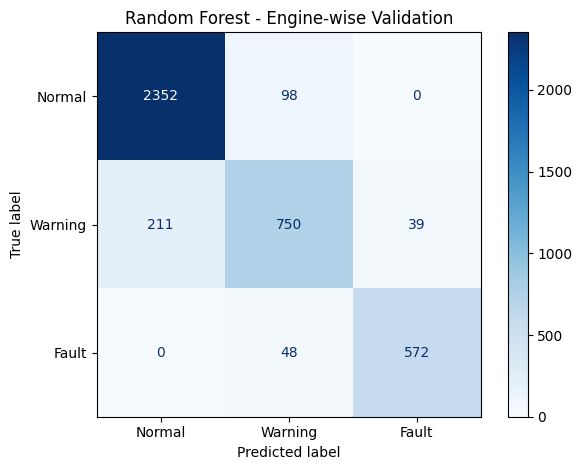


Top 15 important features:


,Feature,Importance
2,sensor_4_last,0.060753
9,sensor_15_last,0.053215
1,sensor_3_last,0.048531
10,sensor_17_last,0.045578
12,sensor_21_last,0.039801
31,sensor_11_std,0.038217
5,sensor_11_last,0.034120
11,sensor_20_last,0.032209
52,sensor_2_max,0.030068
0,sensor_2_last,0.027922


In [25]:

# ============================================================
# STEP 5: RANDOM FOREST CLASSIFICATION
# Engine-wise Train / Validation Split
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Prepare window features and labels
# ------------------------------------------------------------

X = X_train_window
y = y_train_window

# Use engine IDs from the matching window metadata
groups = train_meta["unit"].to_numpy()

assert len(X) == len(y) == len(groups)

# Split by engine, not by individual row
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_fit = X.iloc[train_idx]
y_fit = y[train_idx]

X_val = X.iloc[val_idx]
y_val = y[val_idx]

fit_units = set(groups[train_idx])
val_units = set(groups[val_idx])

assert fit_units.isdisjoint(val_units)

print("Training windows:", len(X_fit))
print("Validation windows:", len(X_val))
print("Overlapping engine units:", len(fit_units & val_units))

print("\nTraining class distribution:")
print(pd.Series(y_fit).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

# ------------------------------------------------------------
# 2. Train the Random Forest baseline
# ------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_fit, y_fit)

# ------------------------------------------------------------
# 3. Evaluate validation performance
# ------------------------------------------------------------

val_pred = rf_model.predict(X_val)

class_names = ["Normal", "Warning", "Fault"]
class_ids = [0, 1, 2]

print("\n===== VALIDATION RESULTS =====")

print(f"Accuracy: {accuracy_score(y_val, val_pred):.4f}")

print(
    "Macro Precision:",
    round(
        precision_score(
            y_val, val_pred,
            labels=class_ids,
            average="macro",
            zero_division=0
        ), 4
    )
)

print(
    "Macro Recall:",
    round(
        recall_score(
            y_val, val_pred,
            labels=class_ids,
            average="macro",
            zero_division=0
        ), 4
    )
)

print(
    "Macro F1-score:",
    round(
        f1_score(
            y_val, val_pred,
            labels=class_ids,
            average="macro",
            zero_division=0
        ), 4
    )
)

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_pred,
    labels=class_ids,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_val, val_pred, labels=class_ids
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(values_format="d", cmap="Blues")

plt.title("Random Forest - Engine-wise Validation")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Feature importance
# ------------------------------------------------------------

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTop 15 important features:")
display(importance.head(15))


In [26]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Detailed validation metrics
print("VALIDATION CLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        val_pred,
        labels=[0, 1, 2],
        target_names=["Normal", "Warning", "Fault"],
        digits=4,
        zero_division=0
    )
)

# Focus specifically on Warning and Fault recall
report = classification_report(
    y_val,
    val_pred,
    labels=[0, 1, 2],
    target_names=["Normal", "Warning", "Fault"],
    output_dict=True,
    zero_division=0
)

print("\nWarning Recall:",
      round(report["Warning"]["recall"], 4))

print("Fault Recall:",
      round(report["Fault"]["recall"], 4))

print("Macro F1-score:",
      round(f1_score(y_val, val_pred, average="macro"), 4))


VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9177    0.9600    0.9384      2450
     Warning     0.8371    0.7500    0.7911      1000
       Fault     0.9362    0.9226    0.9293       620

    accuracy                         0.9027      4070
   macro avg     0.8970    0.8775    0.8863      4070
weighted avg     0.9007    0.9027    0.9008      4070


Warning Recall: 0.75
Fault Recall: 0.9226
Macro F1-score: 0.8863
